# 07 – NLP Component (Non-News Text Only)

**Project:** Technology & Fintech Market Intelligence and Regime Analyzer  
**Phase:** 5 – Bounded NLP component

### Goals
1. Load text based data company / category descriptions only  
2. Preprocess and embed the texts  
3. Compute description similarity across companies  
4. Match textual profiles to market-behaviour (regime) groups  
5. Document coverage and limitations; persist results  

### Explicit exclusions (proposal)
- No news collection  
- No news sentiment  
- No social-media text  

### Prerequisites
- Notebooks 01–03 completed (04 recommended for regime labels)  
- Local MongoDB running  
- `sentence-transformers` optional (TF-IDF fallback is built-in)

In [1]:
# Cell 1 – Imports & setup

from __future__ import annotations

import sys
from pathlib import Path
from typing import Any, Dict, List, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from config import settings, TICKERS, CATEGORIES
from config.tickers import get_primary_category
from config.constants import REGIME_LABELS, RANDOM_SEED
from src.utils import setup_logging, get_logger, utc_now, ensure_dir, save_json
from src.db.connection import get_client, get_db
from src.db.collections import ensure_indexes
from src.db.analysis_results import save_analysis_result
from src.db.company_metadata import get_all_company_metadata

from src.nlp.text_sources import (
    load_company_texts,
    load_category_texts,
    get_text_for_ticker,
)
from src.nlp.preprocessing import preprocess_texts, tokenize_and_clean
from src.nlp.embeddings import embed_texts, get_embedding_model
from src.nlp.similarity import (
    compute_similarity_matrix,
    most_similar_companies,
    match_text_to_regimes,
    keyword_overlap_score,
)

setup_logging(level="INFO")
logger = get_logger(__name__)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (11, 5)
np.random.seed(RANDOM_SEED)

print("Project root :", PROJECT_ROOT)

Project root : c:\Users\hp\Documents\GitHub\BeneathTheMarket


In [2]:
## 1. Load validated universe & regime labels (if available)

processed_dir = ensure_dir(settings.PROCESSED_DATA_DIR)
keep_path = processed_dir / "validated_tickers.csv"

if keep_path.exists():
    keep_df = pd.read_csv(keep_path)
    VALIDATED_TICKERS = keep_df["ticker"].str.upper().tolist()
else:
    VALIDATED_TICKERS = list(TICKERS)
    print("validated_tickers.csv not found – using full candidate list")

print(f"Tickers in scope: {len(VALIDATED_TICKERS)}")

# Optional: load discovered regimes from notebook 04
regime_labels: Dict[str, str] = {}
panel_path = processed_dir / "feature_panel_with_regimes.parquet"
if panel_path.exists():
    panel = pd.read_parquet(panel_path)
    if "regime_discovered" in panel.columns:
        # most frequent regime per ticker
        regime_labels = (
            panel.groupby("ticker")["regime_discovered"]
            .agg(lambda s: s.mode().iloc[0] if len(s.mode()) else None)
            .dropna()
            .to_dict()
        )
        print(f"Regime labels loaded for {len(regime_labels)} tickers")
    else:
        print("Panel found but no regime_discovered column")
else:
    print("No regime panel – text-to-regime matching will be limited")

Tickers in scope: 38
Regime labels loaded for 38 tickers


## 2. Load non-news text sources

**Primary source:** company metadata already stored in MongoDB  
(from yfinance `.info` during ingestion) + static category descriptions  
shipped with the project.  

In [3]:
# Cell 3 – Text loading

client = get_client()
db = get_db()
ensure_indexes(db)

# Company-level texts
text_map = load_company_texts(tickers=VALIDATED_TICKERS)
cat_texts = load_category_texts()

coverage = []
for t in VALIDATED_TICKERS:
    raw = text_map.get(t, "")
    coverage.append({
        "ticker": t,
        "category": get_primary_category(t),
        "has_text": bool(raw and raw.strip()),
        "length": len(raw) if raw else 0,
        "preview": (raw[:100] + "…") if raw and len(raw) > 100 else raw,
    })

coverage_df = pd.DataFrame(coverage)
n_with_text = int(coverage_df["has_text"].sum())

print(f"Tickers with non-empty description: {n_with_text} / {len(coverage_df)}")
print(f"Static category descriptions     : {len(cat_texts)}")
display(coverage_df.head(10))

if n_with_text < 10:
    logger.warning(
        "Text coverage is low (%d). NLP conclusions will be limited.",
        n_with_text,
    )

2026-10-12 14:51:36 | INFO     | src.db.connection | Connected to local MongoDB at mongodb://localhost:27017 (db=tech_fintech_market_intel)
2026-10-12 14:51:36 | INFO     | src.db.collections | All MongoDB indexes ensured.
2026-10-12 14:51:36 | INFO     | src.nlp.text_sources | Loaded non-news text for 38/38 tickers
Tickers with non-empty description: 38 / 38
Static category descriptions     : 6


,ticker,category,has_text,length,preview
0,ANET,Cloud and enterprise infrastructure,True,71,"Arista Networks, Inc.. Sector: Technology. Ind..."
1,CSCO,Cloud and enterprise infrastructure,True,75,"Cisco Systems, Inc.. Sector: Technology. Indus..."
2,DELL,Cloud and enterprise infrastructure,True,72,Dell Technologies Inc.. Sector: Technology. In...
3,HPE,Cloud and enterprise infrastructure,True,123,Hewlett Packard Enterprise Company. Hewlett Pa...
4,IBM,Cloud and enterprise infrastructure,True,140,International Business Machines Corporation. I...
5,ORCL,Cloud and enterprise infrastructure,True,76,Oracle Corporation. Sector: Technology. Indust...
6,CRWD,"Data, AI, and digital infrastructure software",True,84,"CrowdStrike Holdings, Inc.. Sector: Technology..."
7,DDOG,"Data, AI, and digital infrastructure software",True,68,"Datadog, Inc.. Sector: Technology. Industry: S..."
8,MDB,"Data, AI, and digital infrastructure software",True,71,"MongoDB, Inc.. Sector: Technology. Industry: S..."
9,NET,"Data, AI, and digital infrastructure software",True,74,"Cloudflare, Inc.. Sector: Technology. Industry..."


In [4]:
## 3. Preprocessing

# Only keep tickers that actually have text
texts_nonempty = {t: txt for t, txt in text_map.items() if txt and txt.strip()}
tokens_map = preprocess_texts(texts_nonempty)

print(f"Preprocessed {len(tokens_map)} documents")
# Show a sample
sample_ticker = next(iter(tokens_map))
print(f"\nSample tokens ({sample_ticker}):")
print(tokens_map[sample_ticker][:30])

Preprocessed 38 documents

Sample tokens (ANET):
['arista', 'networks', 'inc', 'sector', 'technology', 'industry', 'computer', 'hardware']


## 4. Embeddings

Uses `sentence-transformers` when available; otherwise falls back to TF-IDF  
so the notebook still runs in a minimal environment.

In [5]:
# Cell 5 – Embed

ids, embeddings = embed_texts(
    texts_nonempty,
    model_name="all-MiniLM-L6-v2",
    prefer_sentence_transformers=True,
)

print(f"Embedded {len(ids)} texts → shape {embeddings.shape}")
backend, _ = get_embedding_model()
print(f"Backend used: {backend}")

c:\Users\hp\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/attr_value.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
c:\Users\hp\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/tensor.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
c:\Users\hp\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/resour

2026-10-12 14:53:42 | WARNING  | tensorflow | From c:\Users\hp\AppData\Local\Programs\Python\Python313\Lib\site-packages\tf_keras\src\losses.py:2976: The name tf.losses.sparse_softmax_cross_entropy is deprecated. Please use tf.compat.v1.losses.sparse_softmax_cross_entropy instead.

2026-10-12 14:53:43 | INFO     | datasets | TensorFlow version 2.20.0 available.
2026-10-12 14:53:46 | INFO     | sentence_transformers.base.model | No device provided, using cpu
2026-10-12 14:53:47 | INFO     | sentence_transformers.base.model | Loading SentenceTransformer model from sentence-transformers/all-MiniLM-L6-v2.
2026-10-12 14:53:52 | INFO     | src.nlp.embeddings | Loaded sentence-transformers model: all-MiniLM-L6-v2
2026-10-12 14:53:52 | INFO     | src.nlp.embeddings | Embedded 38 texts with sentence_transformers → shape (38, 384)
Embedded 38 texts → shape (38, 384)
Backend used: sentence_transformers


Similarity matrix shape: (38, 38)


,ANET,CSCO,DELL,HPE,IBM,ORCL,CRWD,DDOG
ANET,1.000,0.540,0.409,0.403,0.372,0.480,0.422,0.329
CSCO,0.540,1.000,0.582,0.535,0.502,0.518,0.364,0.329
DELL,0.409,0.582,1.000,0.586,0.431,0.424,0.417,0.284
HPE,0.403,0.535,0.586,1.000,0.442,0.457,0.403,0.321
IBM,0.372,0.502,0.431,0.442,1.000,0.449,0.375,0.400
ORCL,0.480,0.518,0.424,0.457,0.449,1.000,0.559,0.463
CRWD,0.422,0.364,0.417,0.403,0.375,0.559,1.000,0.449
DDOG,0.329,0.329,0.284,0.321,0.400,0.463,0.449,1.000


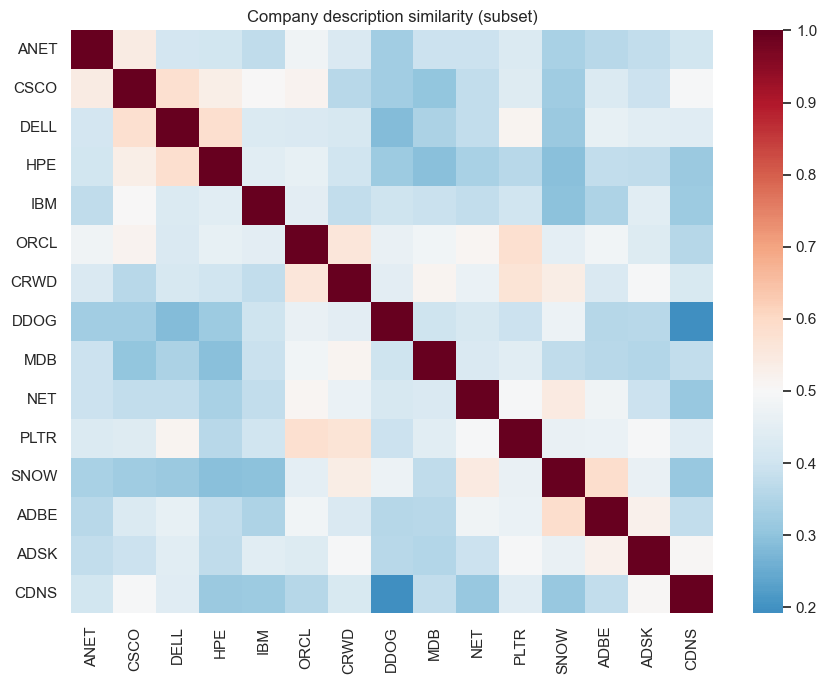

In [6]:
## 5. Company-description similarity matrix

sim_matrix = compute_similarity_matrix(ids, embeddings)
print("Similarity matrix shape:", sim_matrix.shape)
display(sim_matrix.iloc[:8, :8].round(3))

# Heatmap (subset for readability)
subset = ids[:15]
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
    sim_matrix.loc[subset, subset],
    annot=False,
    cmap="RdBu_r",
    center=0.5,
    ax=ax,
)
ax.set_title("Company description similarity (subset)")
plt.tight_layout()
plt.show()

In [7]:
## 6. Nearest neighbours for a few tickers

example_tickers = ids[:6]
nn_rows = []
for t in example_tickers:
    neighbours = most_similar_companies(sim_matrix, t, top_n=5)
    for rank, (other, score) in enumerate(neighbours, 1):
        nn_rows.append({
            "query": t,
            "rank": rank,
            "neighbour": other,
            "similarity": round(score, 4),
            "query_category": get_primary_category(t),
            "neighbour_category": get_primary_category(other),
        })

nn_df = pd.DataFrame(nn_rows)
print("Top-5 nearest neighbours (by description):")
display(nn_df)

Top-5 nearest neighbours (by description):


,query,rank,neighbour,similarity,query_category,neighbour_category
0,ANET,1,CSCO,0.5397,Cloud and enterprise infrastructure,Cloud and enterprise infrastructure
1,ANET,2,ORCL,0.4802,Cloud and enterprise infrastructure,Cloud and enterprise infrastructure
2,ANET,3,MU,0.4740,Cloud and enterprise infrastructure,Semiconductors and chip design
3,ANET,4,SNPS,0.4667,Cloud and enterprise infrastructure,Enterprise software and developer platforms
4,ANET,5,XYZ,0.4652,Cloud and enterprise infrastructure,Fintech and digital financial infrastructure
5,CSCO,1,DELL,0.5824,Cloud and enterprise infrastructure,Cloud and enterprise infrastructure
6,CSCO,2,GOOGL,0.5780,Cloud and enterprise infrastructure,Major technology platforms
7,CSCO,3,AVGO,0.5729,Cloud and enterprise infrastructure,Semiconductors and chip design
8,CSCO,4,TXN,0.5651,Cloud and enterprise infrastructure,Semiconductors and chip design
9,CSCO,5,XYZ,0.5628,Cloud and enterprise infrastructure,Fintech and digital financial infrastructure


## 7. Match textual profiles to market-behaviour regimes

If regime labels from notebook 04 are available, we project company  
embeddings onto regime centroids and report the nearest regime.

In [9]:
# Cell 8 – Text ↔ regime matching

if regime_labels:
    # Restrict to tickers that have both text and a regime label
    common_ids = [t for t in ids if t in regime_labels]
    if common_ids:
        idx = [ids.index(t) for t in common_ids]
        emb_sub = embeddings[idx]
        match_result = match_text_to_regimes(
            common_ids,
            emb_sub,
            regime_labels,
            top_k=5,
        )
        print("Company → nearest regime (by text embedding):")
        nearest = pd.Series(match_result["company_to_nearest_regime"])
        display(
            nearest.value_counts()
            .rename("count")
            .to_frame()
        )

        print("\nTop companies per regime (by cosine to centroid):")
        for regime, pairs in match_result["regime_to_companies"].items():
            print(f"\n  {regime}:")
            for ticker, score in pairs:
                print(f"    {ticker:6s}  {score:.3f}")
    else:
        match_result = {}
        print("No overlap between text ids and regime labels.")
else:
    match_result = {}
    print("No regime labels available – skipping text-to-regime matching.")

2026-10-12 14:57:28 | INFO     | src.nlp.similarity | Matched 38 companies to 4 regimes
Company → nearest regime (by text embedding):


,count
range-bound,17
high-volatility,15
upward-trending,4
downward-trending,2



Top companies per regime (by cosine to centroid):

  range-bound:
    CSCO    0.778
    MSFT    0.777
    AAPL    0.763
    DELL    0.763
    GOOGL   0.760

  high-volatility:
    CRM     0.793
    INTC    0.752
    SNPS    0.730
    NOW     0.711
    MU      0.704

  upward-trending:
    PLTR    0.767
    NET     0.763
    MDB     0.757
    HOOD    0.707

  downward-trending:
    XYZ     0.825
    COIN    0.825


## 8. Keyword-overlap baseline (transparent alternative)

Simple Jaccard overlap on cleaned tokens – useful as a sanity check  
alongside dense embeddings.

In [10]:
# Cell 9 – Keyword overlap example

if len(tokens_map) >= 2:
    t1, t2 = list(tokens_map.keys())[:2]
    jacc = keyword_overlap_score(tokens_map[t1], tokens_map[t2])
    print(f"Jaccard({t1}, {t2}) = {jacc:.3f}")

    # Average within-category vs cross-category overlap
    within, cross = [], []
    tickers_with_tokens = list(tokens_map.keys())
    for i, a in enumerate(tickers_with_tokens):
        for b in tickers_with_tokens[i + 1 :]:
            score = keyword_overlap_score(tokens_map[a], tokens_map[b])
            if get_primary_category(a) == get_primary_category(b):
                within.append(score)
            else:
                cross.append(score)
    print(f"Mean within-category Jaccard : {np.mean(within):.3f} (n={len(within)})")
    print(f"Mean cross-category Jaccard  : {np.mean(cross):.3f} (n={len(cross)})")

Jaccard(ANET, CSCO) = 0.333
Mean within-category Jaccard : 0.456 (n=104)
Mean cross-category Jaccard  : 0.308 (n=599)


In [11]:
## 9. Document limitations & persist results

nlp_summary = {
    "run_at": utc_now().isoformat(),
    "n_tickers_in_scope": len(VALIDATED_TICKERS),
    "n_with_text": n_with_text,
    "text_coverage_pct": round(100 * n_with_text / max(len(VALIDATED_TICKERS), 1), 1),
    "embedding_backend": backend,
    "embedding_dim": int(embeddings.shape[1]) if embeddings.size else 0,
    "n_category_descriptions": len(cat_texts),
    "regime_matching_performed": bool(match_result),
    "source_notes": [
        "Texts come from yfinance company metadata (longName, sector, industry) "
        "and static project-owned category descriptions.",
        "No news articles, headlines or social-media content were used.",
        "NLP output is contextual analysis only – not a causal explanation of price moves.",
    ],
    "limitations": [
        "Description quality and length vary by ticker; some firms have very short text.",
        "Static category descriptions are project-level, not official industry taxonomy.",
        "If sentence-transformers is unavailable the TF-IDF fallback is used.",
        "Text-to-regime matching requires regime labels from notebook 04.",
    ],
}

# Persist
summary_path = processed_dir / "nlp_component_summary.json"
save_json(nlp_summary, summary_path)
print(f"Saved NLP summary → {summary_path}")

# Similarity matrix (small)
sim_path = processed_dir / "nlp_similarity_matrix.csv"
sim_matrix.to_csv(sim_path)
print(f"Saved similarity matrix → {sim_path}")

# MongoDB
save_analysis_result({
    "analysis_type": "nlp_component",
    "as_of": utc_now().isoformat(),
    "payload": {
        "n_with_text": n_with_text,
        "text_coverage_pct": nlp_summary["text_coverage_pct"],
        "embedding_backend": backend,
        "regime_matching_performed": bool(match_result),
        "source_notes": nlp_summary["source_notes"],
        "limitations": nlp_summary["limitations"],
    },
})
print("NLP summary written to MongoDB")

print("\n=== NLP COMPONENT SUMMARY ===")
for k, v in nlp_summary.items():
    if k not in ("source_notes", "limitations"):
        print(f"  {k}: {v}")

Saved NLP summary → C:\Users\hp\Documents\GitHub\BeneathTheMarket\data\processed\nlp_component_summary.json
Saved similarity matrix → C:\Users\hp\Documents\GitHub\BeneathTheMarket\data\processed\nlp_similarity_matrix.csv
NLP summary written to MongoDB

=== NLP COMPONENT SUMMARY ===
  run_at: 2026-10-12T09:28:41.437245+00:00
  n_tickers_in_scope: 38
  n_with_text: 38
  text_coverage_pct: 100.0
  embedding_backend: sentence_transformers
  embedding_dim: 384
  n_category_descriptions: 6
  regime_matching_performed: True


## 10. Acceptance criteria (Notebook 07)

| Criterion | Status |
|-----------|--------|
| Non-news text only | Cells 2-3 |
| Documented source | Cell 10 |
| Preprocessing + embeddings | Cells 4-5 |
| Similarity analysis | Cells 6-7 |
| Optional match to behaviour regimes | Cell 8 |
| Limitations explicitly recorded | Cell 10 |
| Results persisted | Cell 10 |


In [12]:
print("Notebook 07 finished successfully.")
print(f"Text coverage: {n_with_text}/{len(VALIDATED_TICKERS)} tickers")
print(f"Embedding backend: {backend}")

Notebook 07 finished successfully.
Text coverage: 38/38 tickers
Embedding backend: sentence_transformers
